[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/myway0101/see-read-explain-dl/blob/main/notebooks/ch13_gradio.ipynb)

# 13장 내 모델을 웹 데모로 · 실습 노트북
『딥러닝 응용 — 보고, 읽고, 설명하는 딥러닝』

1. Hub에서 모델 가져다 쓰기 (13.3절)
2. 내 모델 준비: 4장 개·고양이 모델 (13.4절)
3. Gradio로 데모 만들기 — 예측 + Grad-CAM (13.5절)
4. 모델 카드 쓰기 (13.6절)

**런타임 → 런타임 유형 변경 → T4 GPU**로 바꾼 뒤 실행하세요. GPU에서 모두 실행하면 10분쯤 걸립니다(데이터 내려받기 포함).
> 이 노트북은 Hugging Face 계정 없이 끝까지 실행됩니다.

## 0. 준비

In [1]:
!pip -q install gradio
import os, zipfile, shutil, time
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import colormaps
from PIL import Image
import tensorflow as tf
from tensorflow.keras import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D
from tensorflow.keras.applications import VGG16
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import gradio as gr
from transformers import pipeline

tf.keras.utils.set_random_seed(42)
print("TensorFlow", tf.__version__, "/ Gradio", gr.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow 2.21.0 / Gradio 6.30.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Hub에서 모델 가져다 쓰기
11장의 BERT, 12장의 SAM처럼 Hugging Face Hub에 올라온 모델은 이름 하나로 내려받아 쓸 수 있습니다.
여기서는 `pipeline`으로 ImageNet 1,000개 범주를 분류하는 비전 트랜스포머(ViT)를 불러와 고양이 사진 한 장을 분류해 봅니다.

In [2]:
!wget -q https://huggingface.co/datasets/huggingface/documentation-images/resolve/main/pipeline-cat-chonk.jpeg -O cat_hub.jpg   # Hugging Face 문서의 예시 사진
clf = pipeline('image-classification', model='google/vit-base-patch16-224')
for r in clf(Image.open('cat_hub.jpg')):
    print(f"{r['label'][:36]:38s} {r['score']:.3f}")

config.json:   0%|          | 0.00/69.7k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  346MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/200 [00:00<?, ?it/s]

preprocessor_config.json:   0%|          | 0.00/160 [00:00<?, ?B/s]

lynx, catamount                        0.433
cougar, puma, catamount, mountain li   0.035
snow leopard, ounce, Panthera uncia    0.032
Egyptian cat                           0.024
tiger cat                              0.023


## 2. 내 모델 준비: 4장 개·고양이 모델
4장과 같은 데이터(고양이·개 각각 학습 1,000장, 검증 500장)로 VGG16 특성 추출 모델을 다시 학습합니다.
4장과 한 가지만 다릅니다. Grad-CAM(5장)을 그리려면 VGG16 안의 `block5_conv3` 층 출력이 필요하므로, `Sequential`로 감싸지 않고 **함수형 API**로 한 겹짜리 모델을 만듭니다.

In [3]:
_URL = 'https://download.microsoft.com/download/3/E/1/3E1C3F21-ECDB-4869-8368-6DEBA77B919F/kagglecatsanddogs_5340.zip'
path_to_zip = tf.keras.utils.get_file('kagglecatsanddogs.zip', origin=_URL, extract=False)  # 약 800MB
PATH = os.path.dirname(path_to_zip)
with zipfile.ZipFile(path_to_zip, 'r') as z:
    z.extractall(PATH)

src = os.path.join(PATH, 'PetImages')
base_dir = os.path.join(PATH, 'cats_and_dogs_filtered')
for cls, name in [('Cat', 'cats'), ('Dog', 'dogs')]:
    files = []
    for i in range(12500):
        p = os.path.join(src, cls, f'{i}.jpg')
        try:
            with Image.open(p) as im:
                im.verify()                               # 깨진 사진은 건너뛴다
            files.append(p)
        except Exception:
            pass
        if len(files) == 1500:
            break
    for split, part in [('train', files[:1000]), ('validation', files[1000:])]:
        d = os.path.join(base_dir, split, name)
        os.makedirs(d, exist_ok=True)
        for p in part:
            shutil.copy(p, d)
train_dir = os.path.join(base_dir, 'train')
valid_dir = os.path.join(base_dir, 'validation')
print({c: len(os.listdir(os.path.join(train_dir, c))) for c in ['cats', 'dogs']},
      {c: len(os.listdir(os.path.join(valid_dir, c))) for c in ['cats', 'dogs']})

824887076/824887076 ━━━━━━━━━━━━━━━━━━━━ 5s 0us/step
{'cats': 1000, 'dogs': 1000} {'cats': 500, 'dogs': 500}


In [4]:
IMG = 160
train_gen = ImageDataGenerator(rescale=1./255, rotation_range=10, width_shift_range=0.1,
                               height_shift_range=0.1, shear_range=0.1, zoom_range=0.1
                               ).flow_from_directory(train_dir, target_size=(IMG, IMG), batch_size=32,
                                                     seed=1, class_mode='categorical')
valid_gen = ImageDataGenerator(rescale=1./255).flow_from_directory(
    valid_dir, target_size=(IMG, IMG), batch_size=32, shuffle=False, class_mode='categorical')
CLASSES = list(train_gen.class_indices)            # ['cats', 'dogs']
print(train_gen.class_indices)

Found 2000 images belonging to 2 classes.
Found 1000 images belonging to 2 classes.
{'cats': 0, 'dogs': 1}


In [5]:
base = VGG16(include_top=False, weights='imagenet', input_shape=(IMG, IMG, 3))
base.trainable = False                              # 합성곱 부분은 고정 (특성 추출)
x = GlobalAveragePooling2D()(base.output)
out = Dense(2, activation='softmax')(x)
model = Model(base.input, out)                      # 함수형 API: block5_conv3을 바로 꺼낼 수 있다
model.compile(loss='categorical_crossentropy', optimizer='adam', metrics=['accuracy'])

t = time.time()
history = model.fit(train_gen, epochs=10, validation_data=valid_gen, verbose=2)
print(f'학습 시간 {time.time() - t:.0f}초')
loss, acc = model.evaluate(valid_gen, verbose=0)
print(f'검증 정확도: {acc:.3f}')

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Epoch 1/10
63/63 - 40s - 637ms/step - accuracy: 0.6350 - loss: 0.6471 - val_accuracy: 0.7720 - val_loss: 0.5733
Epoch 2/10
63/63 - 20s - 319ms/step - accuracy: 0.7705 - loss: 0.5537 - val_accuracy: 0.8050 - val_loss: 0.4983
Epoch 3/10
63/63 - 25s - 399ms/step - accuracy: 0.8070 - loss: 0.4967 - val_accuracy: 0.8230 - val_loss: 0.4514
Epoch 4/10
63/63 - 20s - 311ms/step - accuracy: 0.8190 - loss: 0.4592 - val_accuracy: 0.8450 - val_loss: 0.4180
Epoch 5/10
63/63 - 20s - 310ms/step - accuracy: 0.8370 - loss: 0.4285 - val_accuracy: 0.8550 - val_loss: 0.3925
Epoch 6/10
63/63 - 19s - 309ms/step - accuracy: 0.8415 - loss: 0.4152 - val_accuracy: 0.8610 - val_loss: 0.3736
Epoch 7/10
63/63 - 20s - 311ms/step - accuracy: 0.8480 - loss: 0.3946 - val_accuracy: 0.8620 - val_loss: 0.3595
Epoch 8/10
63/63 - 20s - 310ms/step - accuracy: 0.8545 - loss: 0.3810 - val_accuracy: 0.8730 - val_loss: 0.3476
Epoch 9/10
63/63 - 19s - 309ms/step - accuracy: 0.867

### 파일로 저장하기
학습한 모델은 `.keras` 파일 하나에 구조와 가중치가 함께 저장됩니다. 이 파일만 있으면 다른 컴퓨터에서도 `load_model`로 그대로 불러올 수 있습니다.

In [6]:
os.makedirs('hf_model', exist_ok=True)
model.save('hf_model/cat_dog_vgg16.keras')
print(f"파일 크기: {os.path.getsize('hf_model/cat_dog_vgg16.keras') / 1e6:.1f} MB")

loaded = tf.keras.models.load_model('hf_model/cat_dog_vgg16.keras')     # 다시 불러와서
print('불러온 모델의 검증 정확도:', round(loaded.evaluate(valid_gen, verbose=0)[1], 3))

파일 크기: 59.0 MB
불러온 모델의 검증 정확도: 0.868


## 3. Gradio로 데모 만들기
**사진 한 장을 받아 → 개·고양이 확률과 Grad-CAM 히트맵을 돌려주는 함수** 하나만 만들면, Gradio가 그 함수에 맞는 웹 화면을 만들어 줍니다.
먼저 함수부터 만들고 검증 사진으로 확인합니다. 학습 때와 **똑같이** 160×160으로 줄이고(Keras가 쓰는 NEAREST 방식) 255로 나누는 것이 중요합니다.

검증 1,000장: 맞힌 사진 868장, 그중 확률 0.9 이상 302장, 확률이 0.4~0.6 사이인 애매한 사진 130장
cat {'cat': 0.996, 'dog': 0.004}
dog {'cat': 0.0, 'dog': 1.0}
hard {'cat': 0.473, 'dog': 0.527}


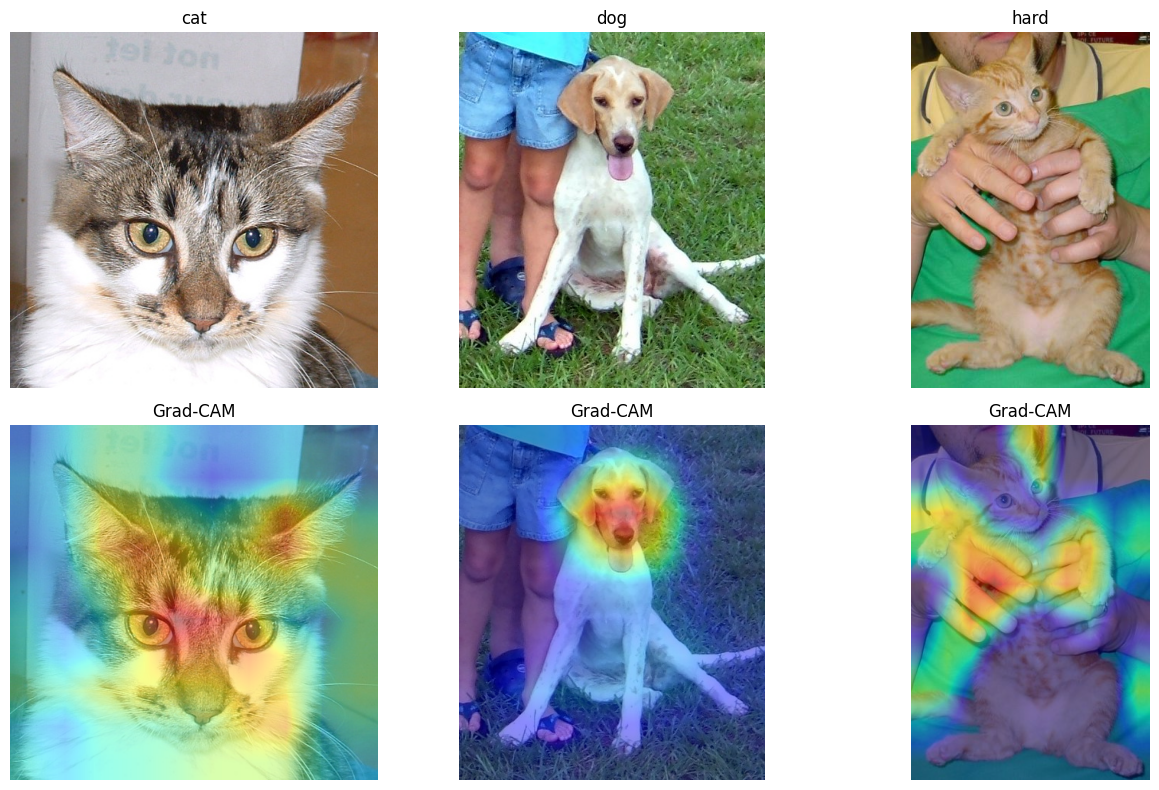

In [7]:
def grad_cam(model, x, class_index, layer_name='block5_conv3'):
    # 5장의 Grad-CAM: 마지막 합성곱층 특성 맵의 가중합 (160×160 입력이면 10×10)
    grad_model = Model(model.input, [model.get_layer(layer_name).output, model.output])
    with tf.GradientTape() as tape:
        conv_out, preds = grad_model(x[np.newaxis])
        score = preds[:, class_index]
    grads = tape.gradient(score, conv_out)[0]
    weights = tf.reduce_mean(grads, axis=(0, 1))
    cam = tf.nn.relu(tf.reduce_sum(conv_out[0] * weights, axis=-1))
    return (cam / (tf.reduce_max(cam) + 1e-8)).numpy()

def predict(img):
    # Gradio가 넘겨주는 PIL 사진 → (확률 딕셔너리, 히트맵을 겹친 사진)
    img = img.convert('RGB')
    x = np.asarray(img.resize((IMG, IMG), Image.NEAREST), dtype='float32') / 255.0   # 학습 때와 같은 전처리
    probs = model.predict(x[np.newaxis], verbose=0)[0]
    k = int(probs.argmax())
    cam = grad_cam(model, x, k)
    heat = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize(img.size, Image.BILINEAR)) / 255.0
    color = colormaps['jet'](heat)[..., :3]
    overlay = (0.55 * np.asarray(img) / 255.0 + 0.45 * color)
    return {'cat': float(probs[0]), 'dog': float(probs[1])}, np.uint8(overlay * 255)

# 검증 사진 1,000장 전체의 예측: 모델이 얼마나 확신하는지 본다
P = model.predict(valid_gen, verbose=0)
y = valid_gen.classes
conf, pred = P.max(1), P.argmax(1)
print(f'검증 1,000장: 맞힌 사진 {(pred == y).sum()}장, 그중 확률 0.9 이상 {((pred == y) & (conf >= 0.9)).sum()}장, '
      f'확률이 0.4~0.6 사이인 애매한 사진 {((conf < 0.6)).sum()}장')

# 데모 예시 세 장: 가장 확신한 고양이 · 개 사진과, 고양이 폴더의 첫 사진
files = np.array(valid_gen.filepaths)
ex = {'cat': files[y == 0][P[y == 0, 0].argmax()],
      'dog': files[y == 1][P[y == 1, 1].argmax()],
      'hard': files[y == 0][0]}
os.makedirs('examples', exist_ok=True)
fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for c, (name, p) in enumerate(ex.items()):
    shutil.copy(p, f'examples/{name}.jpg')
    img = Image.open(p)
    probs, overlay = predict(img)
    print(name, {k: round(v, 3) for k, v in probs.items()})
    axes[0, c].imshow(img); axes[0, c].set_title(name); axes[0, c].axis('off')
    axes[1, c].imshow(overlay); axes[1, c].set_title('Grad-CAM'); axes[1, c].axis('off')
plt.tight_layout()
plt.show()

### 웹 화면 만들기
`gr.Interface`에 **함수, 입력 종류, 출력 종류**를 알려 주면 끝입니다. Colab에서 `share=True`로 띄우면 셀 아래에 데모가 나타나고, `https://….gradio.live` 공유 주소도 함께 나옵니다. 이 주소는 노트북이 실행 중일 때만 열리고, 길어야 1주일 뒤 만료됩니다(Gradio 6.30 기준, 그 기간도 보장되지는 않음).

In [8]:
demo = gr.Interface(
    fn=predict,
    inputs=gr.Image(type='pil', label='사진'),
    outputs=[gr.Label(num_top_classes=2, label='예측'), gr.Image(label='Grad-CAM: 모델이 본 곳')],
    examples=['examples/cat.jpg', 'examples/dog.jpg', 'examples/hard.jpg'],
    title='개 · 고양이 분류기',
    description='4장의 VGG16 전이학습 모델. 사진을 올리면 개·고양이 확률과 모델이 본 곳(Grad-CAM)을 보여 준다.')
demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://0013e359026e4ba35a.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


## 4. 모델 카드 쓰기
모델 카드(README.md)는 Hugging Face 같은 모델 저장소의 첫 화면에 보이는 설명서입니다. 맨 위의 `---` 사이(YAML)에는 라이선스·라이브러리 같은 정보를, 아래에는 무엇을 학습했고 얼마나 잘하며 어디서 틀리는지를 씁니다.

In [9]:
val_acc = round(float(acc), 3)
card = f'''---
license: mit
library_name: keras
tags:
- image-classification
- transfer-learning
---

# 개 · 고양이 분류기 (VGG16 특성 추출)

## 무엇을 하는 모델인가
사진 한 장을 받아 고양이(cat)인지 개(dog)인지 확률을 낸다. 『딥러닝 응용』 4장 실습 모델이다.

## 학습 데이터
Microsoft Kaggle Cats and Dogs 데이터에서 고양이·개 각각 학습 1,000장, 검증 500장. 160×160, 픽셀 값을 255로 나눔.

## 성능
검증 사진 1,000장 정확도 {val_acc}

## 한계
- 개와 고양이만 안다. 다른 사진을 넣어도 둘 중 하나로 답한다.
- 학습 때와 같은 전처리(160×160, ÷255)를 하지 않으면 결과가 틀어진다.
'''
open('hf_model/README.md', 'w').write(card)
print(card)

---
license: mit
library_name: keras
tags:
- image-classification
- transfer-learning
---

# 개 · 고양이 분류기 (VGG16 특성 추출)

## 무엇을 하는 모델인가
사진 한 장을 받아 고양이(cat)인지 개(dog)인지 확률을 낸다. 『딥러닝 응용』 4장 실습 모델이다.

## 학습 데이터
Microsoft Kaggle Cats and Dogs 데이터에서 고양이·개 각각 학습 1,000장, 검증 500장. 160×160, 픽셀 값을 255로 나눔.

## 성능
검증 사진 1,000장 정확도 0.868

## 한계
- 개와 고양이만 안다. 다른 사진을 넣어도 둘 중 하나로 답한다.
- 학습 때와 같은 전처리(160×160, ÷255)를 하지 않으면 결과가 틀어진다.



## 실습
1. **모르는 사진 넣기**: 개도 고양이도 아닌 사진(예: 12장의 트럭 사진)을 `predict`에 넣어 보세요. 확률은 어떻게 나오나요? 모델 카드의 '한계'와 연결해 설명해 보세요.
2. **전처리 실수 재현하기**: `/ 255.0`을 빼고 검증 사진 1,000장을 예측하면 정확도가 어떻게 바뀌나요? 모델은 주로 어느 쪽으로 답하나요?
3. **화면 바꾸기**: `gr.Interface`의 `inputs`에 `gr.Slider(0, 1, value=0.45, label='히트맵 진하기')`를 더하고, `predict`가 그 값을 받아 히트맵을 겹치는 비율로 쓰게 바꿔 보세요.

먼저 직접 작성해 본 뒤, 아래 예시 답안과 비교해 보세요.

In [12]:
# 직접 작성해 보세요



### 예시 답안

In [13]:
# 1. 개도 고양이도 아닌 사진
!wget -q https://raw.githubusercontent.com/facebookresearch/segment-anything/main/notebooks/images/truck.jpg -O truck.jpg
probs, _ = predict(Image.open('truck.jpg'))
print('트럭 사진:', {k: round(v, 3) for k, v in probs.items()})

트럭 사진: {'cat': 0.415, 'dog': 0.585}


In [14]:
# 2. 255로 나누지 않으면 — 검증 사진 1,000장 전체로 비교
X = np.stack([np.asarray(Image.open(p).convert('RGB').resize((IMG, IMG), Image.NEAREST), dtype='float32')
              for p in files])                       # 픽셀 값 0~255 그대로
for name, scale in [('올바른 전처리 (÷255)', 255.0), ('255로 안 나눔', 1.0)]:
    pred_s = model.predict(X / scale, verbose=0).argmax(1)
    print(f'{name}: 정확도 {(pred_s == y).mean():.3f}, cat이라고 답한 사진 {(pred_s == 0).sum()}장, dog라고 답한 사진 {(pred_s == 1).sum()}장')

def predict_wrong(img):
    x = np.asarray(img.convert('RGB').resize((IMG, IMG), Image.NEAREST), dtype='float32')   # / 255.0 을 빠뜨림
    p = model.predict(x[np.newaxis], verbose=0)[0]
    return {'cat': round(float(p[0]), 3), 'dog': round(float(p[1]), 3)}
for name in ['cat', 'dog', 'hard']:
    print(name, '올바른 전처리:', {k: round(v, 3) for k, v in predict(Image.open(f'examples/{name}.jpg'))[0].items()},
          '/ 255로 안 나눔:', predict_wrong(Image.open(f'examples/{name}.jpg')))

올바른 전처리 (÷255): 정확도 0.868, cat이라고 답한 사진 542장, dog라고 답한 사진 458장
255로 안 나눔: 정확도 0.800, cat이라고 답한 사진 300장, dog라고 답한 사진 700장
cat 올바른 전처리: {'cat': 0.996, 'dog': 0.004} / 255로 안 나눔: {'cat': 1.0, 'dog': 0.0}
dog 올바른 전처리: {'cat': 0.0, 'dog': 1.0} / 255로 안 나눔: {'cat': 0.0, 'dog': 1.0}
hard 올바른 전처리: {'cat': 0.473, 'dog': 0.527} / 255로 안 나눔: {'cat': 0.0, 'dog': 1.0}


In [15]:
# 3. 히트맵 진하기 슬라이더
def predict2(img, alpha):
    probs, _ = predict(img)
    img = img.convert('RGB')
    x = np.asarray(img.resize((IMG, IMG), Image.NEAREST), dtype='float32') / 255.0
    cam = grad_cam(model, x, int(np.argmax([probs['cat'], probs['dog']])))
    heat = np.asarray(Image.fromarray(np.uint8(cam * 255)).resize(img.size, Image.BILINEAR)) / 255.0
    over = (1 - alpha) * np.asarray(img) / 255.0 + alpha * colormaps['jet'](heat)[..., :3]
    return probs, np.uint8(over * 255)

demo2 = gr.Interface(predict2, [gr.Image(type='pil'), gr.Slider(0, 1, value=0.45, label='히트맵 진하기')],
                     [gr.Label(num_top_classes=2), gr.Image()], examples=[['examples/cat.jpg', 0.45]])
# demo2.launch(share=True)   # 실행해 보려면 주석을 푼다